<div dir="rtl">

# مینی‌پروژه ۱ — رگرسیون با شبکه‌ی عصبی MLP

هدف این پروژه، اجرای یک مسیر کامل **Deep Learning برای رگرسیون جدولی** است:

**دریافت داده ← بررسی و آماده‌سازی ← بصری‌سازی ← تقسیم داده ← پیش‌پردازش ← طراحی MLP ← آموزش ← کنترل Overfitting ← تنظیم Hyperparameterها ← ارزیابی نهایی ← Cross-Validation ← تحلیل Robustness**

داده‌ی پروژه، داده‌ی **مصرف سوخت و انتشار CO₂ خودروها در کانادا** است. متغیر هدف، مقدار `CO2 emissions (g/km)` است.

در این Notebook سه بخش اصلی داریم:

1. **آماده‌سازی داده**
2. **طراحی و آموزش MLP**
3. **ارزیابی و تحلیل مدل**

</div>

<div dir="rtl">

# ۱. آماده‌سازی داده

این بخش شامل **Acquisition، بررسی اولیه، پیش‌پردازش اولیه، بصری‌سازی ورودی‌ها و Target، ایجاد Missing Data کنترل‌شده، و تقسیم Training / Validation / Test** است.
</div>

<div dir="rtl">

## ۱.۱ کتابخانه‌ها و تنظیمات اولیه

در این پروژه، `pandas` و `numpy` برای داده، `matplotlib` و `seaborn` برای نمودار، `scikit-learn` برای پیش‌پردازش و تقسیم داده، و `TensorFlow / Keras` برای ساخت و آموزش شبکه‌ی عصبی استفاده می‌شوند.

برای One-Hot Encoding از `OneHotEncoder` و برای اتصال آن به متغیرهای عددی و دسته‌ای از `ColumnTransformer` استفاده می‌کنیم. این کار از کدگذاری دستی جلوگیری می‌کند و باعث می‌شود مراحل پیش‌پردازش قابل‌تکرار باشند.
</div>

In [1]:
# در Google Colab معمولاً کتابخانه‌های اصلی از قبل نصب هستند.
# فقط در صورت مشاهده‌ی خطای نصب، خط زیر را فعال کنید:
# !pip -q install pandas numpy matplotlib seaborn scikit-learn tensorflow

import io
import os
import json
import ast
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display

from sklearn.model_selection import train_test_split, KFold
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

print("TensorFlow:", tf.__version__)
print("Pandas:", pd.__version__)
print("Scikit-learn:", __import__("sklearn").__version__)


TensorFlow: 2.22.0-rc0
Pandas: 3.0.6
Scikit-learn: 1.9.1


<div dir="rtl">

## ۱.۲ ایجاد تفاوت کنترل‌شده بین دانشجویان و ساخت داده‌ی گمشده

شماره‌ی دانشجویی خود را وارد کنید.

از انتهای شماره‌ی دانشجویی یک `SEED` می‌سازیم تا آزمایش‌ها برای هر دانشجو قابل‌تکرار باشند. سپس به‌صورت **کنترل‌شده و تصادفی** در بعضی ویژگی‌های ورودی مقدار `NaN` ایجاد می‌کنیم.

متغیر هدف (`CO2 emissions`) را خراب نمی‌کنیم. هدف این قسمت، ایجاد یک سناریوی آموزشی برای بررسی **Robustness مدل نسبت به Missing Data** است.
</div>

In [2]:
# شماره‌ی دانشجویی خود را وارد کنید.
student_id = "123456789"

# seed برای قابل‌تکرار بودن تقسیم‌ها، حذف داده و آموزش
SEED = int(student_id[-6:]) if student_id[-6:].isdigit() else 123456

# برای دانشجویان مختلف، نرخ Missing Data بین 5 تا 20 درصد تغییر می‌کند.
MISSING_RATE = 0.05 + 0.05 * (SEED % 4)

keras.utils.set_random_seed(SEED)
np.random.seed(SEED)

print("Student ID =", student_id)
print("SEED =", SEED)
print("Personalized missing rate =", f"{MISSING_RATE:.0%}")


Student ID = 123456789
SEED = 456789
Personalized missing rate = 10%


<div dir="rtl">

## ۱.۳ دریافت داده

سه روش برای دریافت فایل در نظر گرفته شده است:

- `web`: خواندن مستقیم CSV از منبع رسمی
- `upload`: آپلود CSV از داخل Colab
- `drive`: خواندن فایل از Google Drive

در حالت عادی فقط `DATA_SOURCE` را تغییر دهید.
</div>

In [3]:
DATA_SOURCE = "web"

# لینک مستقیم فایل رسمی داده‌ی Canadian Fuel Consumption Ratings
WEB_URL = (
    "https://open.canada.ca/data/dataset/98f1a129-f628-4ce4-b24d-6f16bf24dd64/"
    "resource/9df1b18d-d036-4783-a61c-99f1f75b3ac5/download/"
    "my2026-fuel-consumption-ratings.csv"
)


In [4]:
if DATA_SOURCE == "web":
    df = pd.read_csv(WEB_URL)

elif DATA_SOURCE == "upload":
    from google.colab import files
    uploaded = files.upload()
    filename = next(iter(uploaded))
    df = pd.read_csv(io.BytesIO(uploaded[filename]))

elif DATA_SOURCE == "drive":
    from google.colab import drive
    drive.mount("/content/drive")
    drive_path = input("مسیر فایل CSV در Google Drive را وارد کنید: ")
    df = pd.read_csv(drive_path)

else:
    raise ValueError("DATA_SOURCE باید web، upload یا drive باشد.")

print("ابعاد داده:", df.shape)
display(df.head())


ابعاد داده: (613, 15)


,Model year,Make,Model,Vehicle class,Engine size (L),Cylinders,Transmission,Fuel type,City (L/100 km),Highway (L/100 km),Combined (L/100 km),Combined (mpg),CO2 emissions (g/km),CO2 rating,Smog rating
0,2026,Acura,ADX AWD,Station wagon: Small,1.5,4,AV7,Z,9.1,7.7,8.5,33,199,5,5
1,2026,Acura,Integra A-SPEC,Full-size,1.5,4,AV7,Z,8.0,6.3,7.3,39,171,6,6
2,2026,Acura,Integra A-SPEC,Full-size,1.5,4,M6,Z,8.9,6.5,7.8,36,181,6,5
3,2026,Acura,Integra Type S,Full-size,2.0,4,M6,Z,11.1,8.3,9.9,29,230,5,5
4,2026,Acura,MDX SH-AWD,Sport utility vehicle: Small,3.5,6,AS10,Z,12.6,9.4,11.2,25,263,4,4


<div dir="rtl">

## ۱.۴ شناخت اولیه‌ی داده

در این مرحله هنوز مدل‌سازی انجام نمی‌دهیم. ابتدا ساختار جدول را می‌شناسیم:

- تعداد سطر و ستون
- نام و نوع ستون‌ها
- مقدارهای گمشده
- تعداد مقادیر یکتا
- سطرهای تکراری
- خلاصه‌ی آماری

این مرحله بخشی از **Data Understanding** است و قبل از هر تصمیم مدلسازی انجام می‌شود.
</div>

In [5]:
print("تعداد سطر و ستون:", df.shape)

print("\nنام ستون‌ها:")
print(df.columns.tolist())

print("\nنوع داده‌ی ستون‌ها:")
display(df.dtypes.to_frame("dtype"))

print("\n۱۰ سطر اول:")
display(df.head(10))

print("\nیک نمونه‌ی تصادفی از داده:")
display(df.sample(min(10, len(df)), random_state=SEED))


تعداد سطر و ستون: (613, 15)

نام ستون‌ها:
['Model year', 'Make', 'Model', 'Vehicle class', 'Engine size (L)', 'Cylinders', 'Transmission', 'Fuel type', 'City (L/100 km)', 'Highway (L/100 km)', 'Combined (L/100 km)', 'Combined (mpg)', 'CO2 emissions (g/km)', 'CO2 rating', 'Smog rating']

نوع داده‌ی ستون‌ها:


,dtype
Model year,int64
Make,str
Model,str
Vehicle class,str
Engine size (L),float64
Cylinders,int64
Transmission,str
Fuel type,str
City (L/100 km),float64
Highway (L/100 km),float64



۱۰ سطر اول:


,Model year,Make,Model,Vehicle class,Engine size (L),Cylinders,Transmission,Fuel type,City (L/100 km),Highway (L/100 km),Combined (L/100 km),Combined (mpg),CO2 emissions (g/km),CO2 rating,Smog rating
0,2026,Acura,ADX AWD,Station wagon: Small,1.5,4,AV7,Z,9.1,7.7,8.5,33,199,5,5
1,2026,Acura,Integra A-SPEC,Full-size,1.5,4,AV7,Z,8.0,6.3,7.3,39,171,6,6
2,2026,Acura,Integra A-SPEC,Full-size,1.5,4,M6,Z,8.9,6.5,7.8,36,181,6,5
3,2026,Acura,Integra Type S,Full-size,2.0,4,M6,Z,11.1,8.3,9.9,29,230,5,5
4,2026,Acura,MDX SH-AWD,Sport utility vehicle: Small,3.5,6,AS10,Z,12.6,9.4,11.2,25,263,4,4
5,2026,Acura,MDX SH-AWD Type S,Sport utility vehicle: Standard,3.0,6,AS10,Z,13.8,11.2,12.4,23,291,4,4
6,2026,Acura,RDX SH-AWD,Sport utility vehicle: Small,2.0,4,AS10,Z,11.0,8.6,9.9,29,232,5,5
7,2026,Acura,RDX SH-AWD A-SPEC,Sport utility vehicle: Small,2.0,4,AS10,Z,11.3,9.1,10.3,27,241,5,5
8,2026,Alfa Romeo,Giulia,Mid-size,2.0,4,A8,Z,10.0,7.2,8.7,32,205,5,4
9,2026,Alfa Romeo,Giulia AWD,Mid-size,2.0,4,A8,Z,10.5,7.7,9.2,31,217,5,4



یک نمونه‌ی تصادفی از داده:


,Model year,Make,Model,Vehicle class,Engine size (L),Cylinders,Transmission,Fuel type,City (L/100 km),Highway (L/100 km),Combined (L/100 km),Combined (mpg),CO2 emissions (g/km),CO2 rating,Smog rating
383,2026,Lexus,RX 500h AWD,Sport utility vehicle: Small,2.4,4,AS6,Z,8.7,8.4,8.6,33,199,5,6
62,2026,BMW,M850i xDrive Coupe,Subcompact,4.4,8,AS8,Z,14.1,9.9,12.2,23,284,4,2
421,2026,Mercedes-Benz,AMG GLE 53 4MATIC+ Coupe,Sport utility vehicle: Standard,3.0,6,A9,Z,13.2,10.7,12.1,23,282,4,6
252,2026,GMC,Yukon XL,Sport utility vehicle: Standard,5.3,8,A10,X,15.7,12.0,14.0,20,329,3,6
24,2026,Audi,Q3 TFSI quattro,Sport utility vehicle: Small,2.0,4,AM7,X,10.8,8.1,9.6,29,225,5,6
83,2026,Buick,Encore GX AWD,Sport utility vehicle: Small,1.3,3,A9,X,9.2,8.4,8.8,32,206,5,6
381,2026,Lexus,RX 350 AWD,Sport utility vehicle: Small,2.4,4,AS8,Z,11.2,8.3,9.9,29,230,5,6
419,2026,Mercedes-Benz,AMG GLC 43 4MATIC Coupe,Station wagon: Small,2.0,4,A9,Z,12.3,9.2,10.9,26,256,4,4
521,2026,Rolls-Royce,Cullinan,Sport utility vehicle: Standard,6.7,12,AS8,Z,19.7,12.4,16.4,17,379,2,2
86,2026,Cadillac,CT4,Compact,2.0,4,AS8,Z,10.6,7.3,9.1,31,214,5,6


In [6]:
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Model year,613.0,NaN,NaN,NaN,2026.0,0.0,2026.0,2026.0,2026.0,2026.0,2026.0
Make,613,37,Mercedes-Benz,53,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Model,613,519,Silverado 4WD,4,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Vehicle class,613,13,Sport utility vehicle: Small,157,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Engine size (L),613.0,NaN,NaN,NaN,2.983687,1.227941,1.2,2.0,2.7,3.5,6.7
Cylinders,613.0,NaN,NaN,NaN,5.399674,1.831586,3.0,4.0,4.0,6.0,12.0
Transmission,613,19,AS8,148,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fuel type,613,4,Z,300,NaN,NaN,NaN,NaN,NaN,NaN,NaN
City (L/100 km),613.0,NaN,NaN,NaN,12.022023,3.452685,4.4,9.6,12.0,14.3,23.5
Highway (L/100 km),613.0,NaN,NaN,NaN,9.285808,2.266554,4.4,7.5,9.0,10.7,16.6


<div dir="rtl">

### بررسی Missing Data
</div>

In [7]:
missing_table = (
    pd.DataFrame({
        "missing_count": df.isna().sum(),
        "missing_percent": 100 * df.isna().mean(),
        "dtype": df.dtypes.astype(str)
    })
    .sort_values("missing_count", ascending=False)
)
display(missing_table)

,missing_count,missing_percent,dtype
Model year,0,0.0,int64
Make,0,0.0,str
Model,0,0.0,str
Vehicle class,0,0.0,str
Engine size (L),0,0.0,float64
Cylinders,0,0.0,int64
Transmission,0,0.0,str
Fuel type,0,0.0,str
City (L/100 km),0,0.0,float64
Highway (L/100 km),0,0.0,float64


<div dir="rtl">

### بررسی سطرهای تکراری و مقادیر یکتا
</div>

In [8]:
duplicate_count = df.duplicated().sum()
print("تعداد سطرهای تکراری:", duplicate_count)

unique_table = pd.DataFrame({
    "unique_values": df.nunique(dropna=False),
    "dtype": df.dtypes.astype(str)
}).sort_values("unique_values")

display(unique_table)

تعداد سطرهای تکراری: 0


,unique_values,dtype
Model year,1,int64
Fuel type,4,str
Cylinders,6,int64
Smog rating,6,int64
CO2 rating,8,int64
Vehicle class,13,str
Transmission,19,str
Engine size (L),30,float64
Make,37,str
Combined (mpg),45,int64


<div dir="rtl">

## ۱.۵ آماده‌سازی اولیه برای EDA

در فایل CSV بعضی ستون‌های عددی ممکن است هنگام خواندن به شکل `object` وارد شوند. آن‌ها را به عدد تبدیل می‌کنیم. اگر مقدار قابل تبدیل نباشد، `NaN` تولید می‌شود و بعداً درباره‌ی نحوه‌ی برخورد با آن تصمیم می‌گیریم.

همچنین ویژگی‌هایی را که از نظر مفهومی نشت اطلاعات ایجاد می‌کنند، از ورودی مدل کنار می‌گذاریم. برای مثال `CO2 rating` و `Smog rating` مستقیماً با خروجی مرتبط‌اند و برای یک پروژه‌ی آموزشی بهتر است به‌عنوان ورودی استفاده نشوند.
</div>

In [ ]:
df_plot = df.copy()

numeric_candidates = [
    "Model year",
    "Engine size (L)",
    "Cylinders",
    "City (L/100 km)",
    "Highway (L/100 km)",
    "Combined (L/100 km)",
    "Combined (mpg)",
    "CO2 emissions (g/km)",
    "CO2 rating",
    "Smog rating",
]

for col in numeric_candidates:
    if col in df_plot.columns:
        df_plot[col] = pd.to_numeric(df_plot[col], errors="coerce")

TARGET = "CO2 emissions (g/km)"

NUMERIC_FEATURES = [
    "Model year",
    "Engine size (L)",
    "Cylinders",
    "City (L/100 km)",
    "Highway (L/100 km)",
    "Combined (L/100 km)",
]

CATEGORICAL_FEATURES = [
    "Vehicle class",
    "Transmission",
    "Fuel type",
]

NUMERIC_FEATURES = [c for c in NUMERIC_FEATURES if c in df_plot.columns]
CATEGORICAL_FEATURES = [c for c in CATEGORICAL_FEATURES if c in df_plot.columns]
FEATURES = NUMERIC_FEATURES + CATEGORICAL_FEATURES

print("Target:", TARGET)
print("Numeric features:", NUMERIC_FEATURES)
print("Categorical features:", CATEGORICAL_FEATURES)
display(df_plot[FEATURES + [TARGET]].head())

Target: CO2 emissions (g/km)
Numeric features: ['Model year', 'Engine size (L)', 'Cylinders', 'City (L/100 km)', 'Highway (L/100 km)', 'Combined (L/100 km)']
Categorical features: ['Vehicle class', 'Transmission', 'Fuel type']


,Model year,Engine size (L),Cylinders,City (L/100 km),Highway (L/100 km),Combined (L/100 km),Vehicle class,Transmission,Fuel type,CO2 emissions (g/km)
0,2026,1.5,4,9.1,7.7,8.5,Station wagon: Small,AV7,Z,199
1,2026,1.5,4,8.0,6.3,7.3,Full-size,AV7,Z,171
2,2026,1.5,4,8.9,6.5,7.8,Full-size,M6,Z,181
3,2026,2.0,4,11.1,8.3,9.9,Full-size,M6,Z,230
4,2026,3.5,6,12.6,9.4,11.2,Sport utility vehicle: Small,AS10,Z,263


<div dir="rtl">

## ۱.۶ بصری‌سازی ورودی‌ها و متغیر هدف

در این بخش چند نمودار با هدف مشخص رسم می‌کنیم. قرار نیست هر ستونی را به نمودار تبدیل کنیم؛ هدف EDA، پیدا کردن الگو، رابطه، توزیع و مقدارهای غیرعادی است.

در گزارش می‌توانید از همین نمودارها برای توضیح این نکته استفاده کنید که چرا بعضی ویژگی‌ها برای پیش‌بینی CO₂ مفید به نظر می‌رسند.
</div>

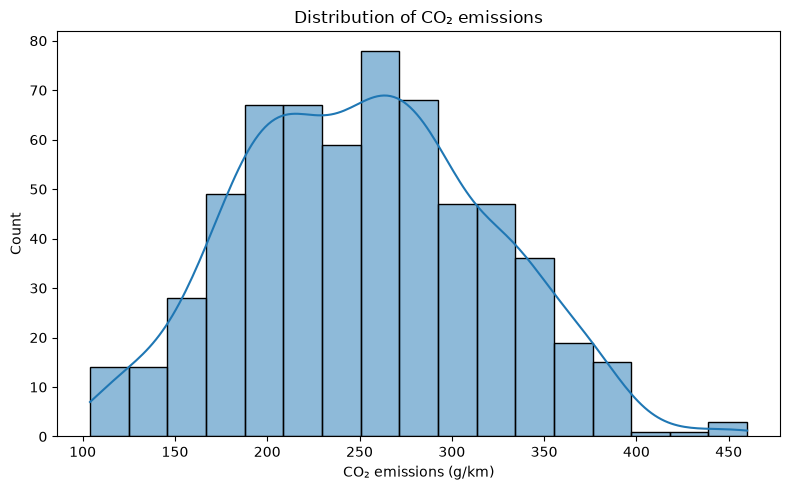

In [10]:
plt.figure(figsize=(8, 5))
sns.histplot(df_plot[TARGET].dropna(), kde=True)
plt.title("Distribution of CO₂ emissions")
plt.xlabel("CO₂ emissions (g/km)")
plt.ylabel("Count")
plt.tight_layout()
plt.show()

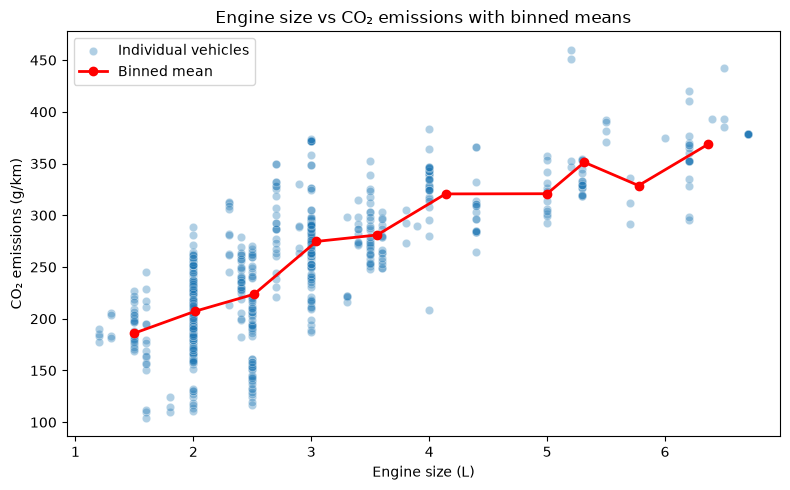

,Engine size bin,mean_engine_size,mean_co2,count
0,"(1.194, 1.75]",1.493878,185.836735,49
1,"(1.75, 2.3]",2.014815,207.271605,162
2,"(2.3, 2.85]",2.514530,223.700855,117
3,"(2.85, 3.4]",3.043478,274.739130,115
4,"(3.4, 3.95]",3.558000,280.960000,50
5,"(3.95, 4.5]",4.138776,320.673469,49
6,"(4.5, 5.05]",5.000000,320.846154,13
7,"(5.05, 5.6]",5.315385,351.230769,26
8,"(5.6, 6.15]",5.775000,328.750000,4
9,"(6.15, 6.7]",6.364286,368.571429,28


In [11]:
# Keep rows with valid values for both variables
plot_data = df_plot[["Engine size (L)", TARGET]].dropna().copy()

# Divide engine size into 10 equal-width bins, then calculate each bin's mean
plot_data["Engine size bin"] = pd.cut(plot_data["Engine size (L)"], bins=10)

binned_means = (
    plot_data.groupby("Engine size bin", observed=True)
    .agg(
        mean_engine_size=("Engine size (L)", "mean"),
        mean_co2=(TARGET, "mean"),
        count=(TARGET, "size")
    )
    .reset_index()
)

plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=plot_data,
    x="Engine size (L)",
    y=TARGET,
    alpha=0.35,
    label="Individual vehicles"
)

# Overlay the mean CO₂ emission in each engine-size bin
plt.plot(
    binned_means["mean_engine_size"],
    binned_means["mean_co2"],
    color="red",
    marker="o",
    linewidth=2,
    label="Binned mean"
)

plt.title("Engine size vs CO₂ emissions with binned means")
plt.xlabel("Engine size (L)")
plt.ylabel("CO₂ emissions (g/km)")
plt.legend()
plt.tight_layout()
plt.show()

display(binned_means)

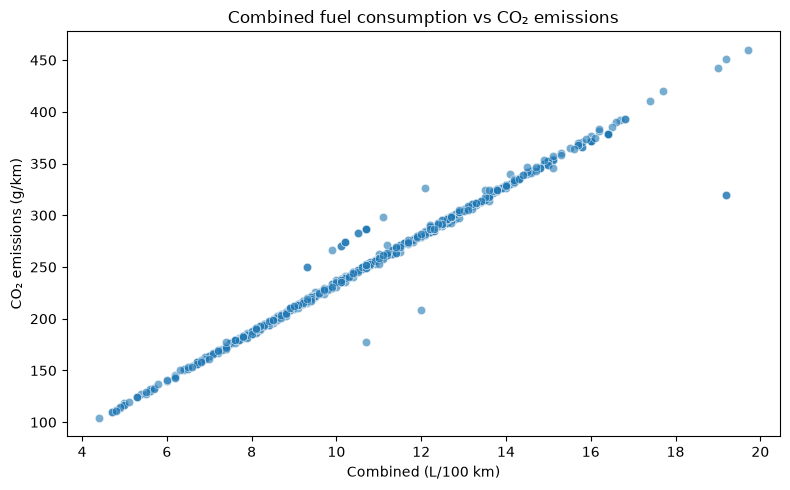

In [12]:
plt.figure(figsize=(8, 5))
sns.scatterplot(
    data=df_plot,
    x="Combined (L/100 km)",
    y=TARGET,
    alpha=0.6
)
plt.title("Combined fuel consumption vs CO₂ emissions")
plt.xlabel("Combined (L/100 km)")
plt.ylabel("CO₂ emissions (g/km)")
plt.tight_layout()
plt.show()


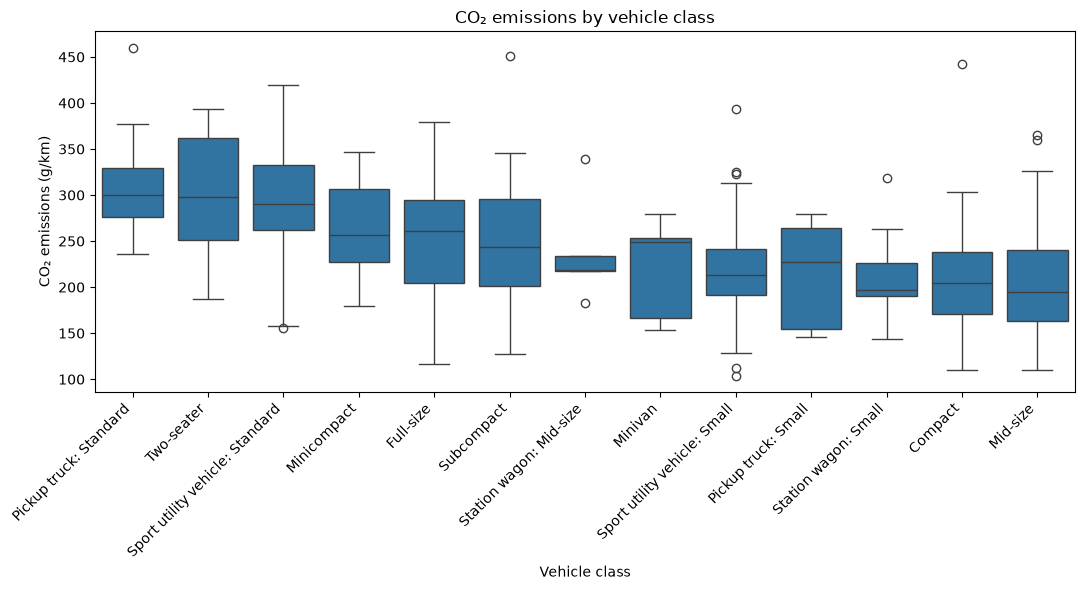

In [13]:
order = (
    df_plot.groupby("Vehicle class")[TARGET]
    .mean()
    .sort_values(ascending=False)
    .index
)

plt.figure(figsize=(11, 6))
sns.boxplot(
    data=df_plot,
    x="Vehicle class",
    y=TARGET,
    order=order
)
plt.xticks(rotation=45, ha="right")
plt.title("CO₂ emissions by vehicle class")
plt.xlabel("Vehicle class")
plt.ylabel("CO₂ emissions (g/km)")
plt.tight_layout()
plt.show()


<div dir="rtl">

### پرسش‌های EDA

بعد از دیدن نمودارها به این پرسش‌ها جواب دهید:

1. کدام متغیر عددی رابطه‌ی واضح‌تری با CO₂ دارد؟
2. آیا بعضی کلاس‌های خودرو میانگین انتشار متفاوتی دارند؟
3. آیا مقدار پرت یا نمونه‌ی غیرعادی دیده می‌شود؟
4. چرا `CO2 rating` را مستقیماً به‌عنوان ورودی انتخاب نکردیم؟
5. کدام نتیجه از نمودار قابل مشاهده است که از روی `head()` به‌راحتی دیده نمی‌شود؟
</div>

<div dir="rtl">

## ۱.۷ پاک‌سازی پایه و ایجاد سناریوی Missing Data

ابتدا سطرهای کاملاً تکراری را حذف می‌کنیم. سپس نسخه‌ی پایه را نگه می‌داریم و فقط در **ویژگی‌های ورودی** به‌صورت تصادفی Missing Data ایجاد می‌کنیم.

این خراب‌کردن مصنوعی، جایگزین «داده‌ی واقعی ناقص» نیست؛ هدف آن این است که دانشجو بتواند در یک شرایط کنترل‌شده، اثر روش‌های مختلف Missing Data را آزمایش کند.
</div>

In [14]:
df_clean_base = df_plot.copy()

before = len(df_clean_base)
df_clean_base = df_clean_base.drop_duplicates().reset_index(drop=True)

print("تعداد سطرهای حذف‌شده به دلیل تکراری بودن:", before - len(df_clean_base))
print("ابعاد داده‌ی پایه:", df_clean_base.shape)


تعداد سطرهای حذف‌شده به دلیل تکراری بودن: 0
ابعاد داده‌ی پایه: (613, 15)


In [15]:
df_corrupted = df_clean_base.copy()
rng = np.random.default_rng(SEED)

for col in FEATURES:
    mask = rng.random(len(df_corrupted)) < MISSING_RATE
    df_corrupted.loc[mask, col] = np.nan

missing_after = (
    df_corrupted[FEATURES]
    .isna()
    .mean()
    .sort_values(ascending=False)
)

display((100 * missing_after).to_frame("missing_%"))


,missing_%
Model year,11.582382
Combined (L/100 km),11.256117
Fuel type,10.929853
Vehicle class,10.603589
City (L/100 km),10.114192
Transmission,10.114192
Cylinders,9.951060
Engine size (L),9.461664
Highway (L/100 km),8.646003


<div dir="rtl">

### نمایش بصری Missing Data

این نمودار نشان می‌دهد سناریوی Missing Data شخصی‌سازی‌شده برای این دانشجو در هر ویژگی چقدر بوده است.
</div>

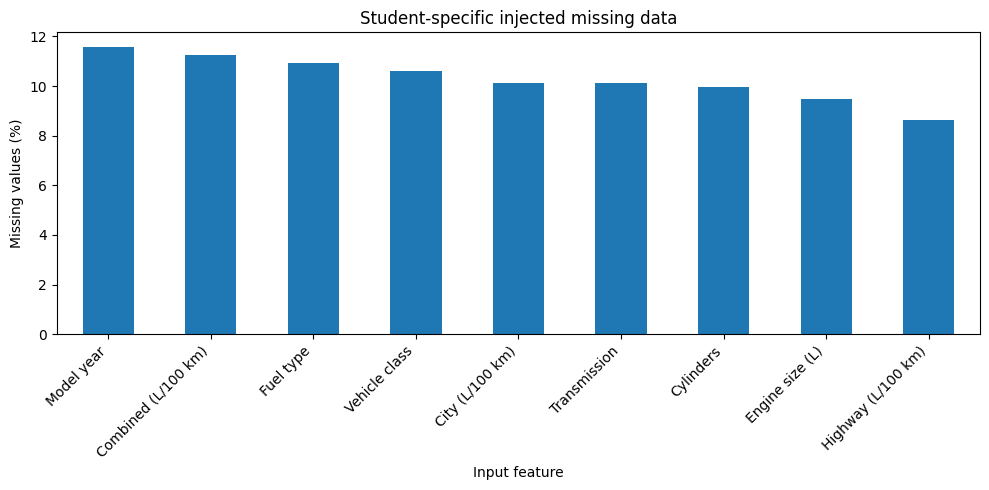

In [16]:
missing_percent = 100 * df_corrupted[FEATURES].isna().mean().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
missing_percent.plot(kind="bar")
plt.ylabel("Missing values (%)")
plt.xlabel("Input feature")
plt.title("Student-specific injected missing data")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


<div dir="rtl">

### مقایسه‌ی روش‌های برخورد با Missing Data

در کنار حذف سطرها و Imputation، یک نمونه‌ی **Interpolation** نیز برای آموزش نشان می‌دهیم. با این حال، چون ترتیب سطرهای خودرو معنای زمانی یا مکانی مشخصی ندارد، Interpolation در این داده از نظر مفهومی بهترین انتخاب نیست و فقط برای مقایسه‌ی آموزشی استفاده می‌شود.
</div>

In [17]:
df_interpolate = df_corrupted.copy()

for col in NUMERIC_FEATURES:
    df_interpolate[col] = df_interpolate[col].interpolate(limit_direction="both")

for col in CATEGORICAL_FEATURES:
    mode = df_interpolate[col].mode(dropna=True)
    if len(mode):
        df_interpolate[col] = df_interpolate[col].fillna(mode.iloc[0])

print("تعداد Missing پس از Interpolation/Mode:")
display(df_interpolate[FEATURES].isna().sum().to_frame("missing_count"))


تعداد Missing پس از Interpolation/Mode:


,missing_count
Model year,0
Engine size (L),0
Cylinders,0
City (L/100 km),0
Highway (L/100 km),0
Combined (L/100 km),0
Vehicle class,0
Transmission,0
Fuel type,0


<div dir="rtl">

## ۱.۸ تقسیم Training / Validation / Test

سه مجموعه‌ی جدا داریم:

- **Training:** یادگیری وزن‌های شبکه
- **Validation:** انتخاب معماری و Hyperparameterها و بررسی Overfitting
- **Test:** ارزیابی نهایی؛ این بخش نباید در تصمیم‌گیری‌های مدل استفاده شود.

در ابتدا ۲۰٪ را برای Test کنار می‌گذاریم؛ از ۸۰٪ باقی‌مانده، ۲۰٪ برای Validation جدا می‌شود. بنابراین سهم نهایی تقریباً **۶۴٪ Train، ۱۶٪ Validation و ۲۰٪ Test** است.
</div>

In [18]:
X = df_corrupted[FEATURES].copy()
y = pd.to_numeric(df_corrupted[TARGET], errors="coerce")

valid_target = y.notna()
X = X.loc[valid_target].reset_index(drop=True)
y = y.loc[valid_target].reset_index(drop=True)

X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED
)

X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.20, random_state=SEED
)

split_table = pd.DataFrame({
    "Split": ["Train", "Validation", "Test"],
    "Rows": [len(X_train), len(X_val), len(X_test)],
    "Percent": [
        100 * len(X_train) / len(X),
        100 * len(X_val) / len(X),
        100 * len(X_test) / len(X)
    ]
})

display(split_table)


,Split,Rows,Percent
0,Train,392,63.947798
1,Validation,98,15.986949
2,Test,123,20.065253


<div dir="rtl">

### بصری‌سازی Train / Validation / Test

فقط تعداد نمونه‌ها کافی نیست. توزیع Target را نیز بین سه بخش بررسی می‌کنیم تا ببینیم تقسیم تصادفی، شکل کلی هدف را حفظ کرده است.
</div>

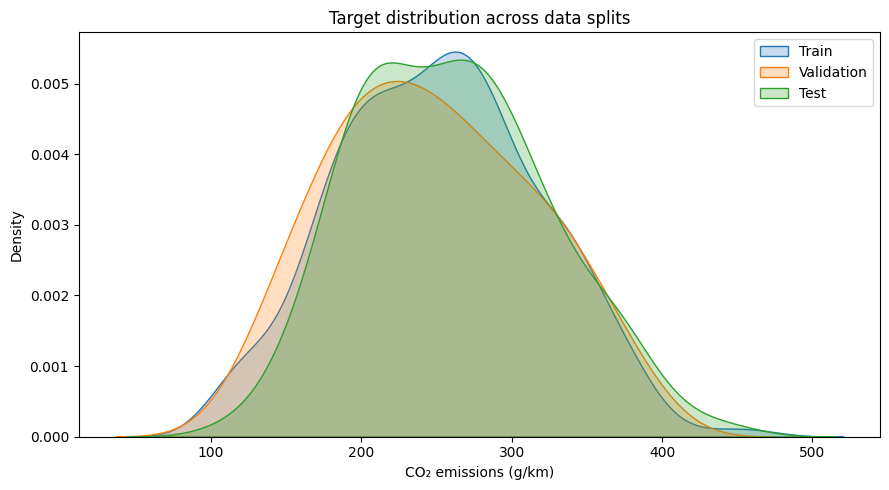

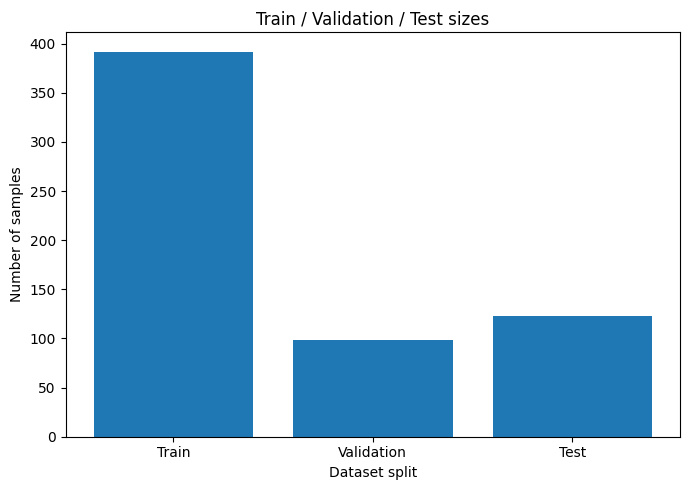

In [19]:
plt.figure(figsize=(9, 5))
sns.kdeplot(y_train, label="Train", fill=True, alpha=0.25)
sns.kdeplot(y_val, label="Validation", fill=True, alpha=0.25)
sns.kdeplot(y_test, label="Test", fill=True, alpha=0.25)
plt.xlabel("CO₂ emissions (g/km)")
plt.ylabel("Density")
plt.title("Target distribution across data splits")
plt.legend()
plt.tight_layout()
plt.show()

plt.figure(figsize=(7, 5))
plt.bar(split_table["Split"], split_table["Rows"])
plt.xlabel("Dataset split")
plt.ylabel("Number of samples")
plt.title("Train / Validation / Test sizes")
plt.tight_layout()
plt.show()


<div dir="rtl">

## ۱.۹ پیش‌پردازش مناسب برای Deep Learning

شبکه‌ی عصبی باید ورودی عددی با مقیاس مناسب دریافت کند.

**ویژگی‌های عددی:**

`Median Imputation ← StandardScaler`

**ویژگی‌های دسته‌ای:**

`Most Frequent Imputation ← One-Hot Encoding`

نکته‌ی مهم: این مراحل داخل `Pipeline` و `ColumnTransformer` قرار می‌گیرند و فقط روی Training داده Fit می‌شوند. بنابراین اطلاعات Validation و Test وارد محاسبه‌ی میانگین، انحراف معیار یا دسته‌های One-Hot نمی‌شود.

این قسمت عمداً با `scikit-learn` انجام می‌شود؛ استفاده از یک MLP در TensorFlow/Keras به این معنی نیست که باید همه‌ی عملیات Data Preparation را دستی پیاده کنیم.
</div>

In [20]:
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

def make_onehot_encoder():
    # سازگاری با نسخه‌های مختلف scikit-learn
    try:
        return OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    except TypeError:
        return OneHotEncoder(handle_unknown="ignore", sparse=False)

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", make_onehot_encoder())
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, NUMERIC_FEATURES),
        ("cat", categorical_transformer, CATEGORICAL_FEATURES),
    ],
    remainder="drop"
)

X_train_p = preprocessor.fit_transform(X_train).astype("float32")
X_val_p = preprocessor.transform(X_val).astype("float32")
X_test_p = preprocessor.transform(X_test).astype("float32")

print("Processed train shape:", X_train_p.shape)
print("Processed validation shape:", X_val_p.shape)
print("Processed test shape:", X_test_p.shape)


Processed train shape: (392, 41)
Processed validation shape: (98, 41)
Processed test shape: (123, 41)


<div dir="rtl">

# ۲. طراحی و آموزش MLP

در این بخش تمرکز اصلی روی خود شبکه‌ی عصبی است: ساختار لایه‌ها، تابع فعال‌سازی، Loss، Optimizer، Learning Rate، Dropout، Early Stopping، Checkpointing و تحلیل روند Train/Validation.
</div>

<div dir="rtl">
## ۲.۱ طراحی معماری MLP

برای رگرسیون، ساختار کلی شبکه به این صورت است:

**Input Layer ← Hidden Layer(s) ← Output Layer**

تعداد نورون‌های Input برابر تعداد ویژگی‌های نهایی بعد از One-Hot Encoding است.

در لایه‌های مخفی از `ReLU` استفاده می‌کنیم، چون تابعی ساده و رایج برای شبکه‌های چندلایه است. خروجی یک نورون دارد و Activation خاصی روی آن اعمال نمی‌شود تا مقدار پیوسته‌ی CO₂ پیش‌بینی شود.
</div>

In [21]:
def build_mlp(
    input_dim,
    hidden_units=(64, 32, 16),
    activation="relu",
    dropout_rate=0.0,
    learning_rate=1e-3
):
    model = keras.Sequential()
    model.add(layers.Input(shape=(input_dim,)))

    for units in hidden_units:
        model.add(layers.Dense(units, activation=activation))
        if dropout_rate > 0:
            model.add(layers.Dropout(dropout_rate))

    # خروجی یک مقدار پیوسته برای مسئله‌ی Regression است.
    model.add(layers.Dense(1))

    optimizer = keras.optimizers.Adam(learning_rate=learning_rate)

    model.compile(
        optimizer=optimizer,
        loss="mse",
        metrics=[keras.metrics.MeanAbsoluteError(name="mae")]
    )

    return model

model = build_mlp(
    input_dim=X_train_p.shape[1],
    hidden_units=(64, 32, 16),
    activation="relu",
    dropout_rate=0.0,
    learning_rate=1e-3
)

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │         2,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,313 (20.75 KB)

 Trainable params: 5,313 (20.75 KB)

 Non-trainable params: 0 (0.00 B)

<div dir="rtl">

## ۲.۲ مفاهیم اصلی آموزش

### Activation Function
`ReLU(x) = max(0, x)` در لایه‌های مخفی استفاده می‌شود. برای مقایسه، بعداً `Tanh` و `Sigmoid` را نیز امتحان می‌کنیم.

### Loss Function
از **Mean Squared Error (MSE)** استفاده می‌کنیم:

`MSE = mean((y_true - y_pred)^2)`

به همین دلیل خطاهای بزرگ‌تر جریمه‌ی بیشتری می‌گیرند.

### Optimizer
از **Adam** استفاده می‌کنیم. Adam وزن‌ها را بر اساس گرادیان و برآوردهای متحرک آن تنظیم می‌کند.

### Learning Rate
Learning Rate اندازه‌ی گام به‌روزرسانی وزن‌هاست.

- خیلی کوچک ← یادگیری آهسته
- خیلی بزرگ ← یادگیری ناپایدار یا نرسیدن به ناحیه‌ی مناسب
- مقدار مناسب ← کاهش پایدار Loss

در آزمایش‌ها مقدارهای `1e-4`، `1e-3` و `1e-2` را مقایسه می‌کنیم.

### Dropout
مثلاً `dropout_rate=0.20` یعنی در **زمان Training** تقریباً ۲۰٪ از فعال‌سازی‌ها به‌صورت تصادفی غیرفعال می‌شوند. هدف اصلی کاهش وابستگی بیش‌ازحد شبکه به نورون‌های خاص و کمک به کنترل Overfitting است.

در زمان Validation و Dropout ،Test فعال نیست.
</div>

<div dir="rtl">

## ۲.۳ آموزش مدل پایه

ابتدا یک مدل پایه را بدون Dropout اجرا می‌کنیم تا یک نقطه‌ی شروع برای مقایسه‌ی آزمایش‌های بعدی داشته باشیم.
</div>

In [22]:
EPOCHS_BASE = 150
BATCH_SIZE = 32
LEARNING_RATE_BASE = 1e-3

tf.keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

model_base = build_mlp(
    input_dim=X_train_p.shape[1],
    hidden_units=(64, 32, 16),
    activation="relu",
    dropout_rate=0.0,
    learning_rate=LEARNING_RATE_BASE
)

history_base = model_base.fit(
    X_train_p,
    y_train,
    validation_data=(X_val_p, y_val),
    epochs=EPOCHS_BASE,
    batch_size=BATCH_SIZE,
    verbose=1
)


Epoch 1/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 67933.7109 - mae: 251.9525 - val_loss: 65719.8906 - val_mae: 247.4877
Epoch 2/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 67594.1094 - mae: 251.2683 - val_loss: 65318.8438 - val_mae: 246.6662
Epoch 3/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 67043.3672 - mae: 250.1644 - val_loss: 64523.9180 - val_mae: 245.0739
Epoch 4/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 65990.5547 - mae: 248.0699 - val_loss: 63076.5156 - val_mae: 242.1627
Epoch 5/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 64121.8125 - mae: 244.3152 - val_loss: 60544.9141 - val_mae: 237.0009
Epoch 6/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 60874.3633 - mae: 237.6758 - val_loss: 56220.8477 - val_mae: 227.9604
Epoch 7/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 55459.0859 - mae: 226.2302 - val_loss: 49275.7539 - val_mae: 212.7554
Epoch 8/150
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 47046.0938 - mae: 207.3622 - val_los

<div dir="rtl">

## ۲.۴ Training Loss در برابر Validation Loss

این نمودار برای تشخیص Underfitting و Overfitting مهم است.

اگر Training Loss کم شود ولی Validation Loss بعد از مدتی دیگر کاهش پیدا نکند یا افزایش یابد، مدل احتمالاً بیش از حد به داده‌های Training وابسته شده است.
</div>

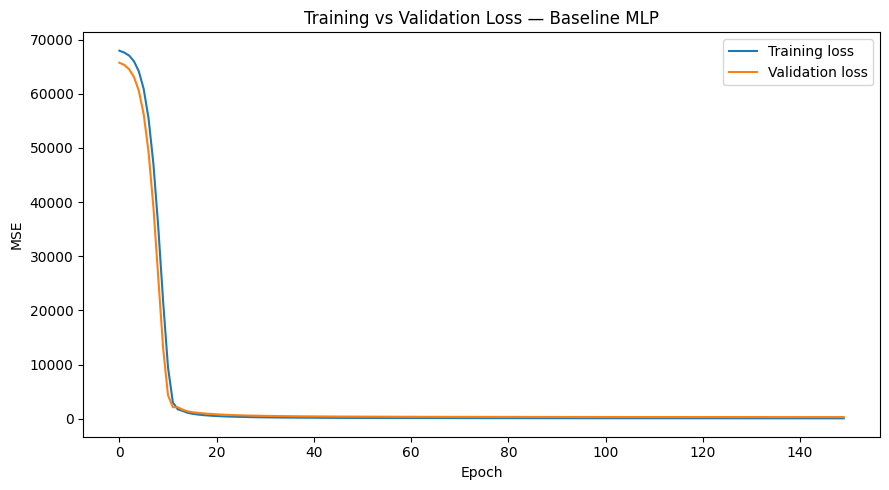

In [23]:
history_base_df = pd.DataFrame(history_base.history)

plt.figure(figsize=(9, 5))
plt.plot(history_base_df["loss"], label="Training loss")
plt.plot(history_base_df["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training vs Validation Loss — Baseline MLP")
plt.legend()
plt.tight_layout()
plt.show()


<div dir="rtl">

## ۲.۵ Early Stopping و Checkpointing

دو ابزار مهم برای آموزش عملی شبکه:

**Early Stopping:** اگر `val_loss` برای چند epoch بهتر نشود، آموزش متوقف می‌شود.

**Checkpointing:** بهترین وزن‌های مدل بر اساس `val_loss` در یک فایل ذخیره می‌شوند.

در نتیجه، لازم نیست آخرین epoch را به‌عنوان بهترین مدل فرض کنیم.
</div>

In [24]:
CHECKPOINT_PATH = f"best_mlp_weights_{SEED}.weights.h5"

tf.keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

model_es = build_mlp(
    input_dim=X_train_p.shape[1],
    hidden_units=(64, 32, 16),
    activation="relu",
    dropout_rate=0.0,
    learning_rate=LEARNING_RATE_BASE
)

early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=CHECKPOINT_PATH,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)

history_es = model_es.fit(
    X_train_p,
    y_train,
    validation_data=(X_val_p, y_val),
    epochs=300,
    batch_size=BATCH_SIZE,
    callbacks=[early_stopping, checkpoint],
    verbose=1
)

print("تعداد epochهای اجراشده:", len(history_es.history["loss"]))
print("Checkpoint:", CHECKPOINT_PATH)


Epoch 1/300
 1/13 ━━━━━━━━━━━━━━━━━━━━ 13s 1s/step - loss: 73425.0312 - mae: 265.0050
Epoch 1: val_loss improved from None to 65719.89062, saving model to best_mlp_weights_456789.weights.h5

Epoch 1: finished saving model to best_mlp_weights_456789.weights.h5
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 67933.7109 - mae: 251.9525 - val_loss: 65719.8906 - val_mae: 247.4877
Epoch 2/300
 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 73113.0781 - mae: 264.4131
Epoch 2: val_loss improved from 65719.89062 to 65318.84375, saving model to best_mlp_weights_456789.weights.h5

Epoch 2: finished saving model to best_mlp_weights_456789.weights.h5
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 67594.1094 - mae: 251.2683 - val_loss: 65318.8438 - val_mae: 246.6662
Epoch 3/300
 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step - loss: 72709.5938 - mae: 263.6482
Epoch 3: val_loss improved from 65318.84375 to 64523.91797, saving model to best_mlp_weights_456789.weights.h5

Epoch 3: finished saving model to bes

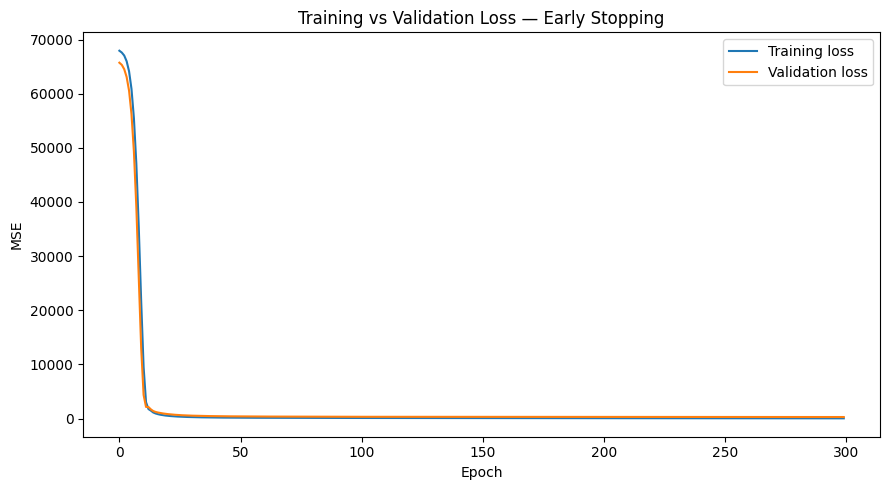

In [43]:
history_es_df = pd.DataFrame(history_es.history)

plt.figure(figsize=(9, 5))
plt.plot(history_es_df["loss"], label="Training loss")
plt.plot(history_es_df["val_loss"], label="Validation loss")
#plt.yscale('log')
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Training vs Validation Loss — Early Stopping")
plt.legend()
plt.tight_layout()
plt.show()


<div dir="rtl">

## ۲.۶ مقایسه‌ی اندازه‌ی شبکه و تابع فعال‌سازی

Hyperparameter اول، معماری شبکه است. شبکه‌ی خیلی کوچک ممکن است Underfit کند و شبکه‌ی خیلی بزرگ ممکن است بیش از حد پیچیده شود.

برای اینکه آزمایش منصفانه باشد، در این مرحله Learning Rate، Batch Size و Early Stopping را ثابت نگه می‌داریم و فقط معماری و Activation را تغییر می‌دهیم.

**نکته‌ی مهم:** مدل‌ها بر اساس Validation مقایسه می‌شوند، نه Test. Test فقط در ارزیابی نهایی استفاده می‌شود.
</div>

In [26]:
ARCHITECTURE_EXPERIMENTS = [
    {"name": "A", "hidden_units": (8,), "activation": "relu"},
    {"name": "B", "hidden_units": (16, 8), "activation": "relu"},
    {"name": "C", "hidden_units": (32, 16), "activation": "relu"},
    {"name": "D", "hidden_units": (64, 32, 16), "activation": "relu"},
    {"name": "E", "hidden_units": (128, 64, 32), "activation": "relu"},
    {"name": "F", "hidden_units": (64, 32, 16), "activation": "tanh"},
    {"name": "G", "hidden_units": (64, 32, 16), "activation": "sigmoid"},
]

def train_on_validation(
    hidden_units,
    activation,
    dropout_rate=0.0,
    learning_rate=1e-3,
    epochs=180
):
    tf.keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    m = build_mlp(
        input_dim=X_train_p.shape[1],
        hidden_units=hidden_units,
        activation=activation,
        dropout_rate=dropout_rate,
        learning_rate=learning_rate
    )

    es = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True,
        verbose=0
    )

    h = m.fit(
        X_train_p, y_train,
        validation_data=(X_val_p, y_val),
        epochs=epochs,
        batch_size=BATCH_SIZE,
        callbacks=[es],
        verbose=0
    )

    pred_val = m.predict(X_val_p, verbose=0).ravel()

    return {
        "model": m,
        "history": h,
        "MAE": mean_absolute_error(y_val, pred_val),
        "RMSE": np.sqrt(mean_squared_error(y_val, pred_val)),
        "R²": r2_score(y_val, pred_val),
    }

architecture_results = []

for exp in ARCHITECTURE_EXPERIMENTS:
    out_exp = train_on_validation(
        hidden_units=exp["hidden_units"],
        activation=exp["activation"],
        dropout_rate=0.0,
        learning_rate=LEARNING_RATE_BASE
    )
    architecture_results.append({
        "name": exp["name"],
        "architecture": str(exp["hidden_units"]),
        "activation": exp["activation"],
        "MAE": out_exp["MAE"],
        "RMSE": out_exp["RMSE"],
        "R²": out_exp["R²"],
        "epochs": len(out_exp["history"].history["loss"])
    })

architecture_table = pd.DataFrame(architecture_results).sort_values("RMSE")
display(architecture_table.reset_index(drop=True))


,name,architecture,activation,MAE,RMSE,R²,epochs
0,E,"(128, 64, 32)",relu,9.392787,15.690206,0.945093,180
1,D,"(64, 32, 16)",relu,9.922824,17.473154,0.931905,180
2,C,"(32, 16)",relu,10.628439,17.679021,0.930291,180
3,B,"(16, 8)",relu,11.866002,19.564205,0.914632,180
4,A,"(8,)",relu,74.036324,78.359149,-0.369470,180
5,F,"(64, 32, 16)",tanh,203.711136,214.433738,-9.255557,180
6,G,"(64, 32, 16)",sigmoid,225.032562,234.783444,-11.294418,180


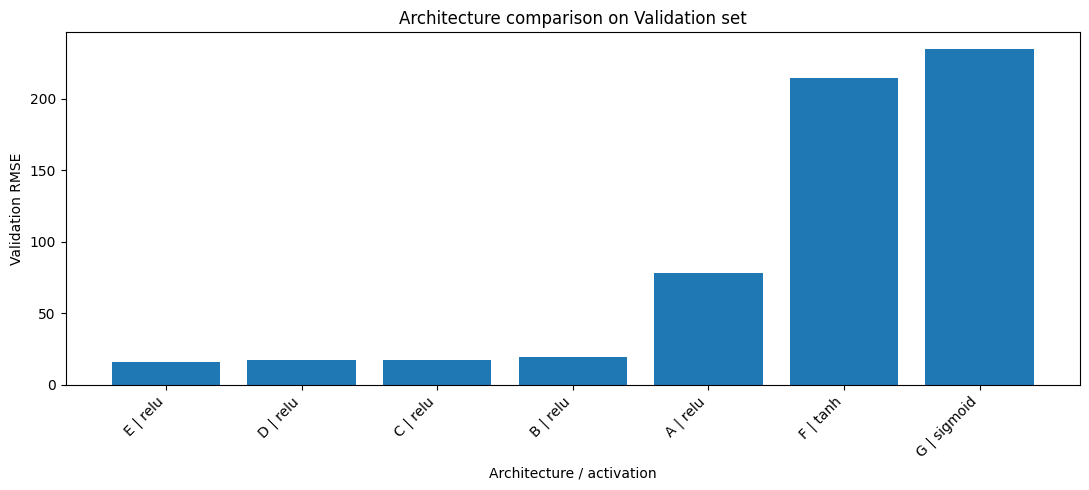

In [27]:
plt.figure(figsize=(11, 5))
labels = architecture_table["name"] + " | " + architecture_table["activation"]
plt.bar(labels, architecture_table["RMSE"])
plt.xlabel("Architecture / activation")
plt.ylabel("Validation RMSE")
plt.title("Architecture comparison on Validation set")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()


<div dir="rtl">

## ۲.۷ آزمایش Dropout

اکنون معماری اصلی را ثابت می‌کنیم و فقط نرخ Dropout را تغییر می‌دهیم.

برای نمونه:

- `0.00` ← بدون Dropout
- `0.10` ← حذف تصادفی حدود ۱۰٪ از activationها در Training
- `0.20`
- `0.30`

هدف پیدا کردن «بیشترین Dropout» نیست؛ هدف دیدن تعادل میان ظرفیت شبکه و Regularization است.
</div>

In [28]:
DROPOUT_RATES = [0.00, 0.10, 0.20, 0.30]
dropout_results = []

for rate in DROPOUT_RATES:
    out_drop = train_on_validation(
        hidden_units=(64, 32, 16),
        activation="relu",
        dropout_rate=rate,
        learning_rate=LEARNING_RATE_BASE
    )
    dropout_results.append({
        "dropout": rate,
        "MAE": out_drop["MAE"],
        "RMSE": out_drop["RMSE"],
        "R²": out_drop["R²"],
        "epochs": len(out_drop["history"].history["loss"])
    })

dropout_table = pd.DataFrame(dropout_results)
display(dropout_table)


,dropout,MAE,RMSE,R²,epochs
0,0.0,9.922824,17.473154,0.931905,180
1,0.1,11.194889,17.925907,0.928330,98
2,0.2,11.949808,18.352590,0.924878,89
3,0.3,15.364949,21.739698,0.894590,57


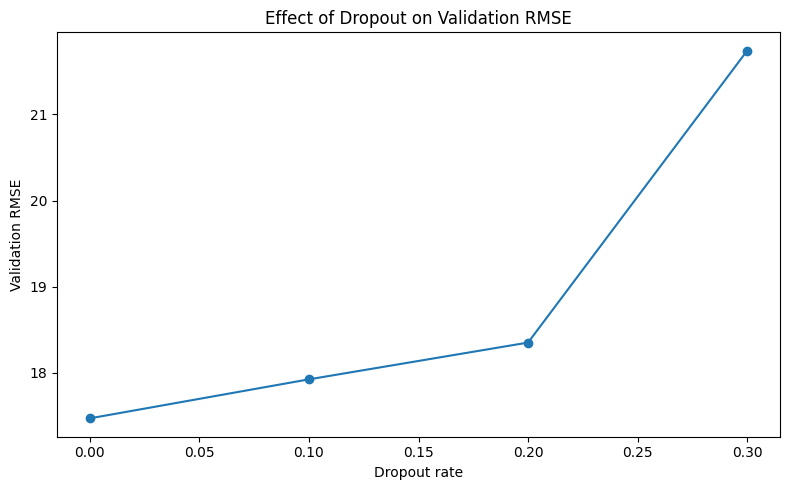

In [29]:
plt.figure(figsize=(8, 5))
plt.plot(dropout_table["dropout"], dropout_table["RMSE"], marker="o")
plt.xlabel("Dropout rate")
plt.ylabel("Validation RMSE")
plt.title("Effect of Dropout on Validation RMSE")
plt.tight_layout()
plt.show()


<div dir="rtl">

## ۲.۸ آزمایش Learning Rate

در این آزمایش فقط Learning Rate را عوض می‌کنیم و بقیه‌ی تنظیمات را ثابت نگه می‌داریم.

مقایسه‌ی اصلی:

`1e-4`، `1e-3` و `1e-2`

این آزمایش کمک می‌کند ببینیم سرعت به‌روزرسانی وزن‌ها چه اثری بر سرعت همگرایی و عملکرد Validation دارد.
</div>

In [30]:
LEARNING_RATES = [1e-4, 1e-3, 1e-2]
learning_rate_results = []

for lr in LEARNING_RATES:
    out_lr = train_on_validation(
        hidden_units=(64, 32, 16),
        activation="relu",
        dropout_rate=0.10,
        learning_rate=lr
    )
    learning_rate_results.append({
        "learning_rate": lr,
        "MAE": out_lr["MAE"],
        "RMSE": out_lr["RMSE"],
        "R²": out_lr["R²"],
        "epochs": len(out_lr["history"].history["loss"])
    })

lr_table = pd.DataFrame(learning_rate_results)
display(lr_table)


,learning_rate,MAE,RMSE,R²,epochs
0,0.0001,20.369831,30.152258,0.797226,180
1,0.0010,11.194889,17.925907,0.928330,98
2,0.0100,11.598945,17.396067,0.932504,65


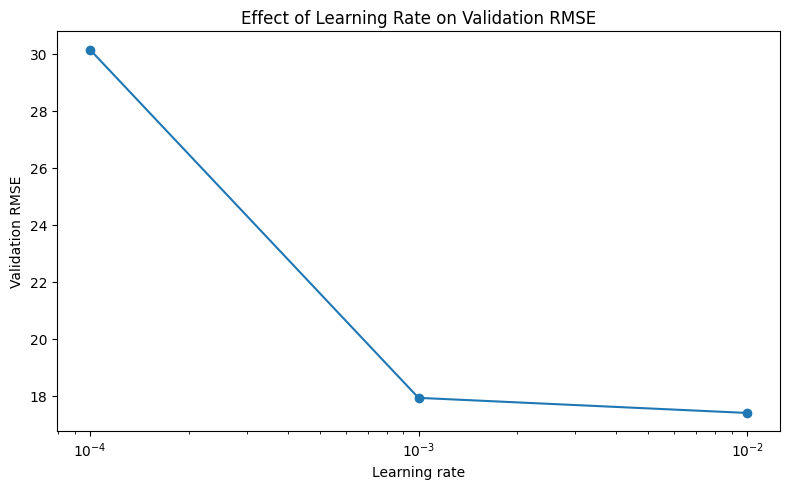

In [31]:
plt.figure(figsize=(8, 5))
plt.semilogx(lr_table["learning_rate"], lr_table["RMSE"], marker="o")
plt.xlabel("Learning rate")
plt.ylabel("Validation RMSE")
plt.title("Effect of Learning Rate on Validation RMSE")
plt.tight_layout()
plt.show()


<div dir="rtl">

## ۲.۹ انتخاب مدل نهایی

بعد از آزمایش‌ها، بهترین تنظیمات را **بر اساس Validation RMSE** انتخاب می‌کنیم. سپس همان تنظیمات را روی مدل نهایی اعمال می‌کنیم و در پایان فقط یک‌بار روی Test ارزیابی می‌کنیم.

این ترتیب مهم است، چون اگر از Test برای انتخاب Hyperparameter استفاده کنیم، Test دیگر یک ارزیابی کاملاً مستقل نخواهد بود.
</div>

In [32]:
best_arch_row = architecture_table.iloc[0]
best_dropout_row = dropout_table.sort_values("RMSE").iloc[0]
best_lr_row = lr_table.sort_values("RMSE").iloc[0]

best_activation = best_arch_row["activation"]
best_architecture = ast.literal_eval(best_arch_row["architecture"])
best_dropout = float(best_dropout_row["dropout"])
best_lr = float(best_lr_row["learning_rate"])

print("Best architecture:", best_architecture)
print("Best activation:", best_activation)
print("Best dropout:", best_dropout)
print("Best learning rate:", best_lr)


Best architecture: (128, 64, 32)
Best activation: relu
Best dropout: 0.0
Best learning rate: 0.01


<div dir="rtl">

## ۲.۱۰ آموزش مدل نهایی و ذخیره‌ی بهترین وزن‌ها

اکنون مدل نهایی را با Hyperparameterهای انتخاب‌شده آموزش می‌دهیم. `ModelCheckpoint` بهترین وزن‌ها را ذخیره می‌کند و `EarlyStopping` مانع آموزش غیرضروری می‌شود.
</div>

In [33]:
FINAL_CHECKPOINT = f"final_mlp_best_{SEED}.weights.h5"

tf.keras.backend.clear_session()
keras.utils.set_random_seed(SEED)

final_model = build_mlp(
    input_dim=X_train_p.shape[1],
    hidden_units=best_architecture,
    activation=best_activation,
    dropout_rate=best_dropout,
    learning_rate=best_lr
)

final_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=20,
    restore_best_weights=True,
    verbose=1
)

final_checkpoint = keras.callbacks.ModelCheckpoint(
    filepath=FINAL_CHECKPOINT,
    monitor="val_loss",
    save_best_only=True,
    save_weights_only=True,
    verbose=1
)

final_history = final_model.fit(
    X_train_p,
    y_train,
    validation_data=(X_val_p, y_val),
    epochs=300,
    batch_size=BATCH_SIZE,
    callbacks=[final_early_stopping, final_checkpoint],
    verbose=1
)

print("Final checkpoint:", FINAL_CHECKPOINT)


Epoch 1/300
 1/13 ━━━━━━━━━━━━━━━━━━━━ 12s 1s/step - loss: 73325.0312 - mae: 264.8024
Epoch 1: val_loss improved from None to 4849.95898, saving model to final_mlp_best_456789.weights.h5

Epoch 1: finished saving model to final_mlp_best_456789.weights.h5
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 25ms/step - loss: 53323.9844 - mae: 217.6055 - val_loss: 4849.9590 - val_mae: 59.7388
Epoch 2/300
 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 6459.1895 - mae: 72.0385
Epoch 2: val_loss did not improve from 4849.95898
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step - loss: 7493.6367 - mae: 64.7019 - val_loss: 5268.5576 - val_mae: 66.5891
Epoch 3/300
 1/13 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step - loss: 7910.3398 - mae: 84.3432
Epoch 3: val_loss improved from 4849.95898 to 1382.84705, saving model to final_mlp_best_456789.weights.h5

Epoch 3: finished saving model to final_mlp_best_456789.weights.h5
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 2838.3459 - mae: 43.4995 - val_loss: 1382.8470 - val_mae: 24.4130
Epoch 4

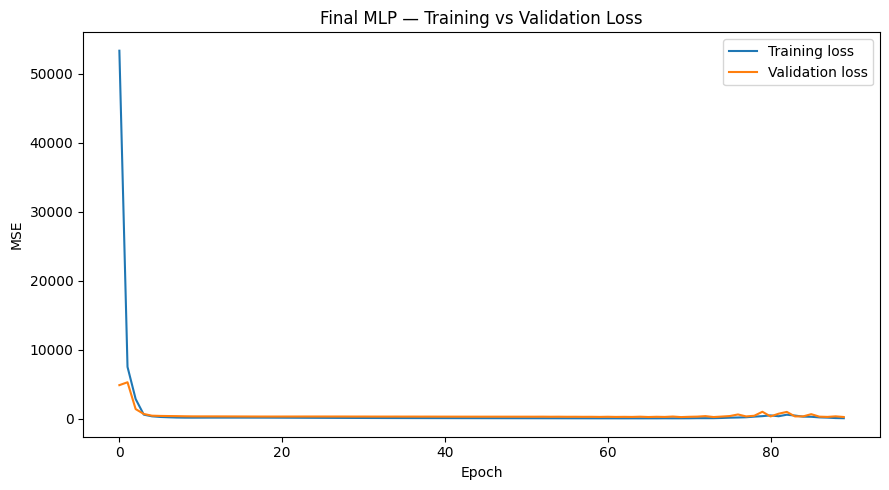

In [44]:
final_hist_df = pd.DataFrame(final_history.history)

plt.figure(figsize=(9, 5))
plt.plot(final_hist_df["loss"], label="Training loss")
plt.plot(final_hist_df["val_loss"], label="Validation loss")
plt.xlabel("Epoch")
plt.ylabel("MSE")
#plt.yscale('log')
plt.title("Final MLP — Training vs Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()


<div dir="rtl">

# ۳. ارزیابی و تحلیل مدل

در این بخش عملکرد نهایی، خطاها، Cross-Validation، Robustness نسبت به Missing Data و نمودارهای نهایی را بررسی می‌کنیم.
</div>

<div dir="rtl">

## ۳.۱ ارزیابی نهایی روی Test

معیارهای اصلی رگرسیون:

**MAE** — میانگین قدرمطلق خطا؛ تفسیر آن مستقیماً با واحد هدف ممکن است.

**RMSE** — ریشه‌ی میانگین مربعات خطا؛ خطاهای بزرگ را بیشتر جریمه می‌کند.

**R²** — سهمی از تغییرات Target که مدل توضیح می‌دهد.

**Adjusted R²** — نسخه‌ای از R² که تعداد ویژگی‌های مدل را نیز در نظر می‌گیرد.

**MAPE** — میانگین درصد قدرمطلق خطا؛ در این داده چون CO₂ مقادیر مثبت دارد قابل استفاده است.

در مقابل، **Precision، Recall و F1** برای Classification هستند و برای این مسئله‌ی Regression معیار مناسبی نیستند؛ بنابراین عمداً آن‌ها را محاسبه نمی‌کنیم.
</div>

In [35]:
y_pred = final_model.predict(X_test_p, verbose=0).ravel()

n = len(y_test)
p = X_test_p.shape[1]

mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))
r2 = r2_score(y_test, y_pred)
mape = np.mean(np.abs((y_test.to_numpy() - y_pred) / y_test.to_numpy())) * 100

if n - p - 1 > 0:
    adjusted_r2 = 1 - (1 - r2) * (n - 1) / (n - p - 1)
else:
    adjusted_r2 = np.nan

within_2 = np.mean(np.abs(y_test.to_numpy() - y_pred) <= 2) * 100

final_metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "R²", "Adjusted R²", "MAPE (%)", "Within ±2 g/km (%)"],
    "Value": [mae, rmse, r2, adjusted_r2, mape, within_2]
})

display(final_metrics)


,Metric,Value
0,MAE,8.593377
1,RMSE,16.588762
2,R²,0.932046
3,Adjusted R²,0.897650
4,MAPE (%),3.511607
5,Within ±2 g/km (%),24.390244


<div dir="rtl">

## ۳.۲ Actual در برابر Predicted و تحلیل Residual

در نمودار اول، هر نقطه یک نمونه‌ی Test است. هرچه نقاط به خط `Actual = Predicted` نزدیک‌تر باشند، پیش‌بینی دقیق‌تر است.

در نمودار دوم:

`Residual = Actual - Predicted`

اگر Residualها الگوی واضح یا شکل خاصی داشته باشند، ممکن است مدل هنوز بخشی از ساختار داده را به‌خوبی یاد نگرفته باشد.
</div>

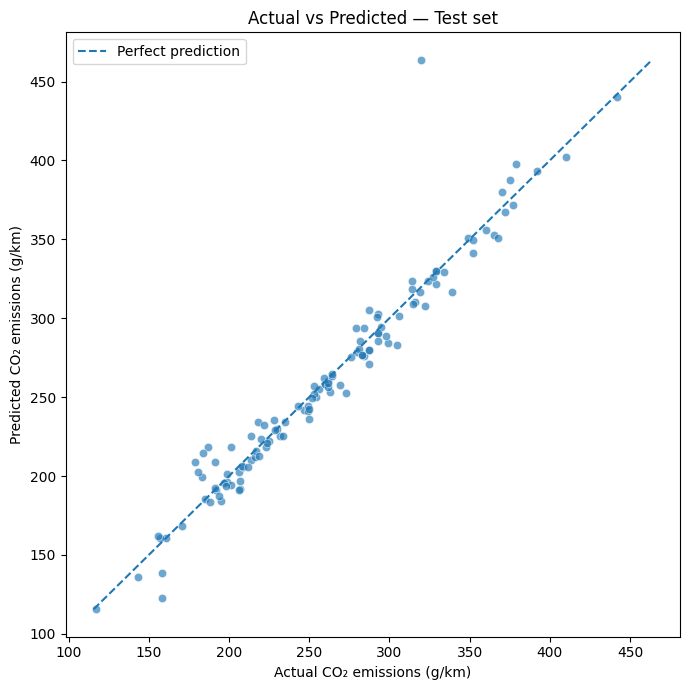

In [36]:
lims = [
    min(float(y_test.min()), float(y_pred.min())),
    max(float(y_test.max()), float(y_pred.max()))
]

plt.figure(figsize=(7, 7))
sns.scatterplot(x=y_test, y=y_pred, alpha=0.65)
plt.plot(lims, lims, "--", label="Perfect prediction")
plt.xlabel("Actual CO₂ emissions (g/km)")
plt.ylabel("Predicted CO₂ emissions (g/km)")
plt.title("Actual vs Predicted — Test set")
plt.legend()
plt.tight_layout()
plt.show()


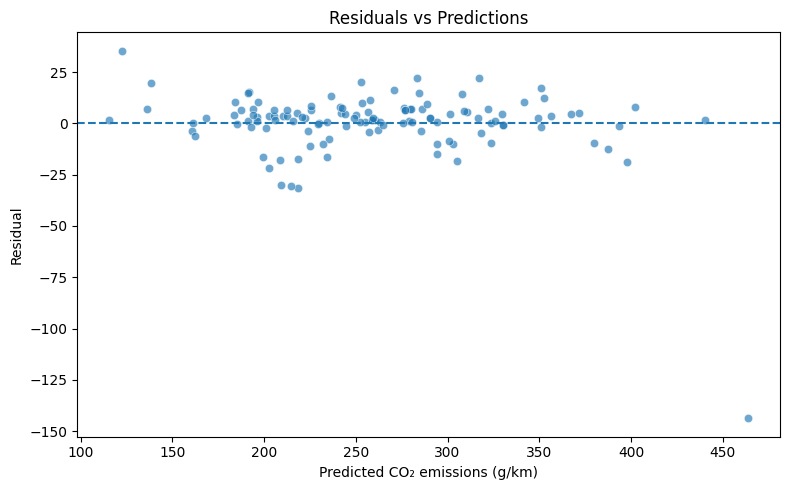

In [37]:
residuals = y_test.to_numpy() - y_pred

plt.figure(figsize=(8, 5))
sns.scatterplot(x=y_pred, y=residuals, alpha=0.65)
plt.axhline(0, linestyle="--")
plt.xlabel("Predicted CO₂ emissions (g/km)")
plt.ylabel("Residual")
plt.title("Residuals vs Predictions")
plt.tight_layout()
plt.show()


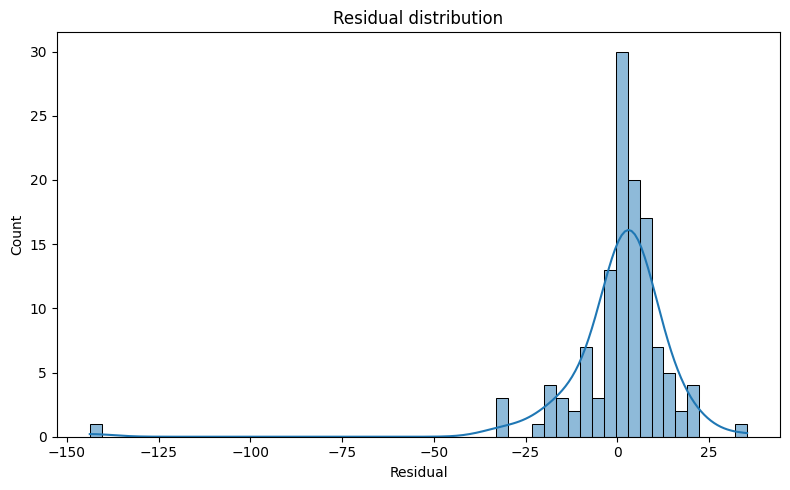

In [38]:
plt.figure(figsize=(8, 5))
sns.histplot(residuals, kde=True)
plt.xlabel("Residual")
plt.ylabel("Count")
plt.title("Residual distribution")
plt.tight_layout()
plt.show()


<div dir="rtl">

## ۳.۳ Cross-Validation با K-Fold

Cross-Validation کمک می‌کند ببینیم عملکرد مدل فقط به یک تقسیم خاص Training/Validation وابسته است یا نه.

در اینجا از **5-Fold Cross-Validation** استفاده می‌کنیم. برای جلوگیری از Data Leakage، در هر Fold، `Imputer` و `Scaler` و `One-Hot Encoder` فقط روی بخش Training همان Fold Fit می‌شوند.

**Test set اصلاً وارد K-Fold نمی‌شود.**
</div>

In [39]:
K_FOLDS = 5
CV_EPOCHS = 150

X_cv = X_trainval.reset_index(drop=True)
y_cv = y_trainval.reset_index(drop=True)

kf = KFold(n_splits=K_FOLDS, shuffle=True, random_state=SEED)

cv_records = []

for fold, (tr_idx, va_idx) in enumerate(kf.split(X_cv), start=1):
    X_tr = X_cv.iloc[tr_idx]
    X_va = X_cv.iloc[va_idx]
    y_tr = y_cv.iloc[tr_idx]
    y_va = y_cv.iloc[va_idx]

    fold_preprocessor = ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), NUMERIC_FEATURES),
            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", make_onehot_encoder())
            ]), CATEGORICAL_FEATURES)
        ],
        remainder="drop"
    )

    X_tr_p = fold_preprocessor.fit_transform(X_tr).astype("float32")
    X_va_p = fold_preprocessor.transform(X_va).astype("float32")

    tf.keras.backend.clear_session()
    keras.utils.set_random_seed(SEED + fold)

    fold_model = build_mlp(
        input_dim=X_tr_p.shape[1],
        hidden_units=best_architecture,
        activation=best_activation,
        dropout_rate=best_dropout,
        learning_rate=best_lr
    )

    fold_es = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=12,
        restore_best_weights=True,
        verbose=0
    )

    fold_history = fold_model.fit(
        X_tr_p, y_tr,
        validation_data=(X_va_p, y_va),
        epochs=CV_EPOCHS,
        batch_size=BATCH_SIZE,
        callbacks=[fold_es],
        verbose=0
    )

    fold_pred = fold_model.predict(X_va_p, verbose=0).ravel()

    cv_records.append({
        "Fold": fold,
        "MAE": mean_absolute_error(y_va, fold_pred),
        "RMSE": np.sqrt(mean_squared_error(y_va, fold_pred)),
        "R²": r2_score(y_va, fold_pred)
    })

cv_table = pd.DataFrame(cv_records)
display(cv_table)
display(cv_table[["MAE", "RMSE", "R²"]].agg(["mean", "std"]).T.rename(columns={
    "mean": "Mean",
    "std": "Std"
}))


,Fold,MAE,RMSE,R²
0,1,9.433923,14.925647,0.950313
1,2,7.610199,13.981946,0.954955
2,3,8.965466,13.130225,0.961698
3,4,9.366325,13.397463,0.963612
4,5,8.879009,13.884318,0.947033


,Mean,Std
MAE,8.850985,0.734648
RMSE,13.863920,0.688749
R²,0.955522,0.007126


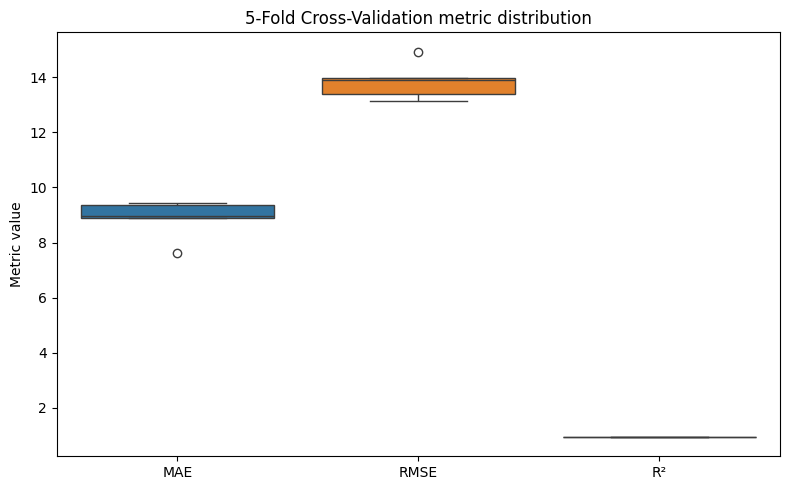

In [40]:
plt.figure(figsize=(8, 5))
sns.boxplot(data=cv_table[["MAE", "RMSE", "R²"]])
plt.title("5-Fold Cross-Validation metric distribution")
plt.ylabel("Metric value")
plt.tight_layout()
plt.show()


<div dir="rtl">

## ۳.۴ بررسی Robustness نسبت به Missing Data

تا اینجا مدل را با Missing Data شخصی‌سازی‌شده آموزش داده‌ایم و Pipeline آن را مدیریت کرده است.

اکنون دو روش ساده را روی همان سناریو مقایسه می‌کنیم:

1. **Drop rows** — هر نمونه‌ای که در ورودی Missing داشته باشد حذف می‌شود.
2. **Imputation** — Missingهای عددی با Median و دسته‌ای با Most Frequent جایگزین می‌شوند.

انتظار آموزشی ما این است که حذف سطرها داده‌ی قابل‌استفاده را کاهش دهد، در حالی که Imputation معمولاً نمونه‌های بیشتری را نگه می‌دارد.
</div>

In [41]:
def train_missing_strategy(df_input, method):
    work = df_input.copy()
    work[TARGET] = pd.to_numeric(work[TARGET], errors="coerce")
    work = work.dropna(subset=[TARGET]).reset_index(drop=True)

    if method == "drop":
        work = work.dropna(subset=FEATURES).reset_index(drop=True)

    Xw = work[FEATURES].copy()
    yw = work[TARGET].copy()

    X_tr, X_te, y_tr, y_te = train_test_split(
        Xw, yw, test_size=0.20, random_state=SEED
    )
    X_tr, X_va, y_tr, y_va = train_test_split(
        X_tr, y_tr, test_size=0.20, random_state=SEED
    )

    prep = ColumnTransformer(
        transformers=[
            ("num", Pipeline([
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler())
            ]), NUMERIC_FEATURES),
            ("cat", Pipeline([
                ("imputer", SimpleImputer(strategy="most_frequent")),
                ("onehot", make_onehot_encoder())
            ]), CATEGORICAL_FEATURES)
        ],
        remainder="drop"
    )

    X_tr_p = prep.fit_transform(X_tr).astype("float32")
    X_va_p = prep.transform(X_va).astype("float32")
    X_te_p = prep.transform(X_te).astype("float32")

    tf.keras.backend.clear_session()
    keras.utils.set_random_seed(SEED)

    m = build_mlp(
        input_dim=X_tr_p.shape[1],
        hidden_units=best_architecture,
        activation=best_activation,
        dropout_rate=best_dropout,
        learning_rate=best_lr
    )

    es = keras.callbacks.EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True,
        verbose=0
    )

    h = m.fit(
        X_tr_p, y_tr,
        validation_data=(X_va_p, y_va),
        epochs=200,
        batch_size=BATCH_SIZE,
        callbacks=[es],
        verbose=0
    )

    pred = m.predict(X_te_p, verbose=0).ravel()

    return {
        "method": method,
        "rows_used": len(work),
        "rows_removed": len(df_input) - len(work),
        "MAE": mean_absolute_error(y_te, pred),
        "RMSE": np.sqrt(mean_squared_error(y_te, pred)),
        "R²": r2_score(y_te, pred),
        "epochs": len(h.history["loss"])
    }

missing_data_results = pd.DataFrame([
    train_missing_strategy(df_corrupted, "drop"),
    train_missing_strategy(df_corrupted, "impute")
])

display(missing_data_results)


,method,rows_used,rows_removed,MAE,RMSE,R²,epochs
0,drop,237,376,6.119419,17.243036,0.911920,200
1,impute,613,0,8.593377,16.588762,0.932046,85


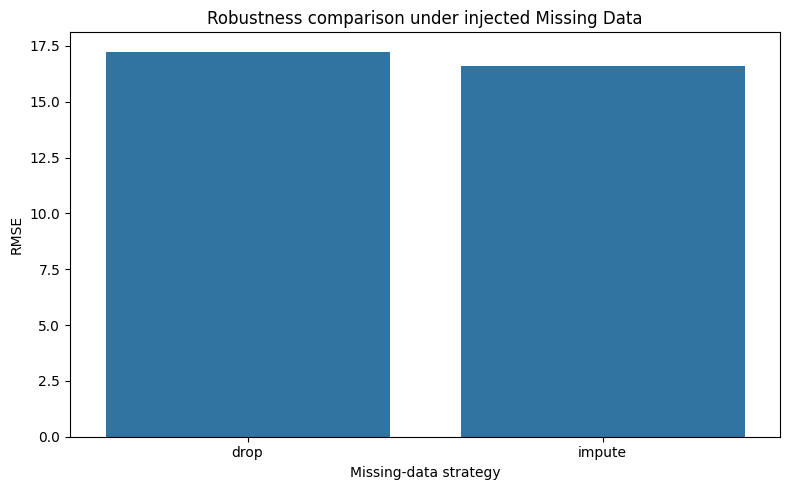

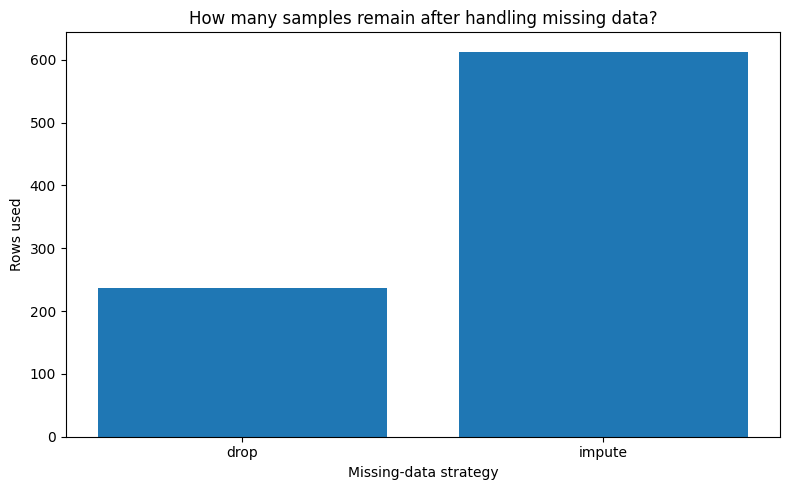

In [42]:
plt.figure(figsize=(8, 5))
sns.barplot(data=missing_data_results, x="method", y="RMSE")
plt.xlabel("Missing-data strategy")
plt.ylabel("RMSE")
plt.title("Robustness comparison under injected Missing Data")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))
plt.bar(missing_data_results["method"], missing_data_results["rows_used"])
plt.xlabel("Missing-data strategy")
plt.ylabel("Rows used")
plt.title("How many samples remain after handling missing data?")
plt.tight_layout()
plt.show()


<div dir="rtl">

## ۳.۵ جمع‌بندی نتایج و نمودارهای مناسب گزارش

برای ارائه‌ی نهایی، حداقل این موارد را نشان دهید:

- منبع و ساختار داده
- منطق ایجاد Missing Data بر اساس `SEED`
- چند نمودار EDA
- نحوه‌ی One-Hot Encoding و Scaling
- معماری MLP
- Activation، MSE، Adam، Learning Rate و Dropout
- Training در برابر Validation Loss
- Early Stopping و Checkpointing
- مقایسه‌ی معماری‌ها
- اثر Dropout و Learning Rate
- MAE، RMSE، R² و در صورت نیاز Adjusted R² / MAPE
- Actual vs Predicted و Residual plot
- میانگین و انحراف معیار 5-Fold CV
- مقایسه‌ی Drop rows با Imputation برای Missing Data

نکته‌ی اصلی در تحلیل، فقط گفتن «کدام عدد بهتر بود» نیست؛ باید توضیح دهید **چرا تغییر معماری، Learning Rate، Dropout یا روش Missing Data باعث تغییر عملکرد شده است.**
</div>

<div dir="rtl">

## ۳.۶ چک‌لیست پیش از تحویل

- [ ] شماره‌ی دانشجویی و `SEED` ثبت شده است.
- [ ] نرخ Missing Data شخصی‌سازی‌شده گزارش شده است.
- [ ] داده‌ی ورودی قبل از مدل‌سازی بررسی شده است.
- [ ] حداقل چند نمودار EDA ارائه شده است.
- [ ] Train / Validation / Test جدا شده‌اند.
- [ ] One-Hot Encoding با `OneHotEncoder` انجام شده است.
- [ ] Imputation و Scaling داخل Pipeline قرار دارند.
- [ ] معماری Input / Hidden / Output توضیح داده شده است.
- [ ] Activation Function توضیح داده شده و مقایسه شده است.
- [ ] Loss و Optimizer توضیح داده شده‌اند.
- [ ] Learning Rate توضیح داده و آزمایش شده است.
- [ ] Dropout توضیح داده و آزمایش شده است.
- [ ] Training و Validation Loss رسم شده است.
- [ ] Early Stopping و Checkpointing اجرا شده‌اند.
- [ ] Test فقط برای ارزیابی نهایی استفاده شده است.
- [ ] MAE، RMSE و R² گزارش شده‌اند.
- [ ] Actual vs Predicted و Residual plot رسم شده‌اند.
- [ ] 5-Fold Cross-Validation اجرا شده است.
- [ ] Robustness نسبت به Missing Data بررسی شده است.
</div>